# Two-Layer Neural Network with Keras (MNIST)
Implement `TwoLayerNetKeras`, train it on the MNIST training set, and test it on the MNIST test set.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

2026-11-17 19:02:09.841254: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Load the MNIST dataset

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test :", X_test.shape, "y_test :", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (60000, 28, 28) y_train: (60000,)
X_test : (10000, 28, 28) y_test : (10000,)


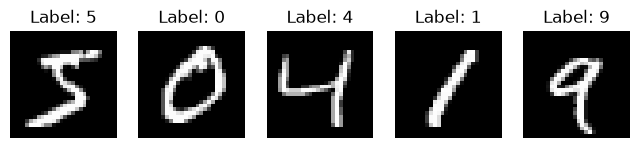

In [3]:
plt.figure(figsize=(8, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.show()

## 2. Preprocess

In [4]:
# flatten 28x28 -> 784 and scale pixels to [0, 1]
X_train = X_train.reshape(-1, 28 * 28).astype("float32") / 255
X_test = X_test.reshape(-1, 28 * 28).astype("float32") / 255
print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (60000, 784) X_test: (10000, 784)


## 3. `TwoLayerNetKeras` class
Two layers = one hidden Dense layer (ReLU) + one output Dense layer (softmax).

In [5]:
class TwoLayerNetKeras:
    def __init__(self, input_size=784, hidden_size=100, output_size=10):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.model = None
        self.history = None

    def create_nn(self):
        self.model = keras.Sequential([
            keras.Input(shape=(self.input_size,)),
            layers.Dense(self.hidden_size, activation="relu"),  # layer 1: hidden
            layers.Dense(self.output_size, activation="softmax"),  # layer 2: output
        ])
        self.model.compile(optimizer="rmsprop",
                           loss="sparse_categorical_crossentropy",  # labels are integers 0-9
                           metrics=["accuracy"])
        self.model.summary()

    def train(self, X, y, epochs=10, batch_size=64, validation_split=0.2):
        self.history = self.model.fit(X, y, epochs=epochs, batch_size=batch_size,
                                      validation_split=validation_split, verbose=2)
        return self.history

    def evaluate(self, X, y):
        return self.model.evaluate(X, y, verbose=0)

    def predict(self, X):
        return np.argmax(self.model.predict(X, verbose=0), axis=1)  # class with highest probability

In [6]:
net = TwoLayerNetKeras(input_size=784, hidden_size=100, output_size=10)
net.create_nn()

I0000 00:00:1794960134.535755 1553971 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14782 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:d8:00.0, compute capability: 7.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train on the MNIST training set

In [7]:
history = net.train(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

Epoch 1/10


2026-11-17 19:02:16.797757: I external/local_xla/xla/service/service.cc:163] XLA service 0x153ff0003d10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-11-17 19:02:16.797775: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): Tesla V100-PCIE-16GB, Compute Capability 7.0
2026-11-17 19:02:16.840876: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-11-17 19:02:17.385170: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92801
I0000 00:00:1794960137.842291 1554227 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


750/750 - 3s - 4ms/step - accuracy: 0.9059 - loss: 0.3393 - val_accuracy: 0.9477 - val_loss: 0.1894
Epoch 2/10
750/750 - 1s - 2ms/step - accuracy: 0.9509 - loss: 0.1682 - val_accuracy: 0.9605 - val_loss: 0.1420
Epoch 3/10
750/750 - 1s - 2ms/step - accuracy: 0.9658 - loss: 0.1200 - val_accuracy: 0.9663 - val_loss: 0.1221
Epoch 4/10
750/750 - 1s - 2ms/step - accuracy: 0.9741 - loss: 0.0931 - val_accuracy: 0.9693 - val_loss: 0.1118
Epoch 5/10
750/750 - 1s - 2ms/step - accuracy: 0.9789 - loss: 0.0756 - val_accuracy: 0.9700 - val_loss: 0.1063
Epoch 6/10
750/750 - 1s - 2ms/step - accuracy: 0.9824 - loss: 0.0631 - val_accuracy: 0.9711 - val_loss: 0.1026
Epoch 7/10
750/750 - 1s - 2ms/step - accuracy: 0.9850 - loss: 0.0537 - val_accuracy: 0.9718 - val_loss: 0.1005
Epoch 8/10
750/750 - 1s - 2ms/step - accuracy: 0.9872 - loss: 0.0459 - val_accuracy: 0.9726 - val_loss: 0.0999
Epoch 9/10
750/750 - 1s - 2ms/step - accuracy: 0.9895 - loss: 0.0395 - val_accuracy: 0.9736 - val_loss: 0.0996
Epoch 10/10


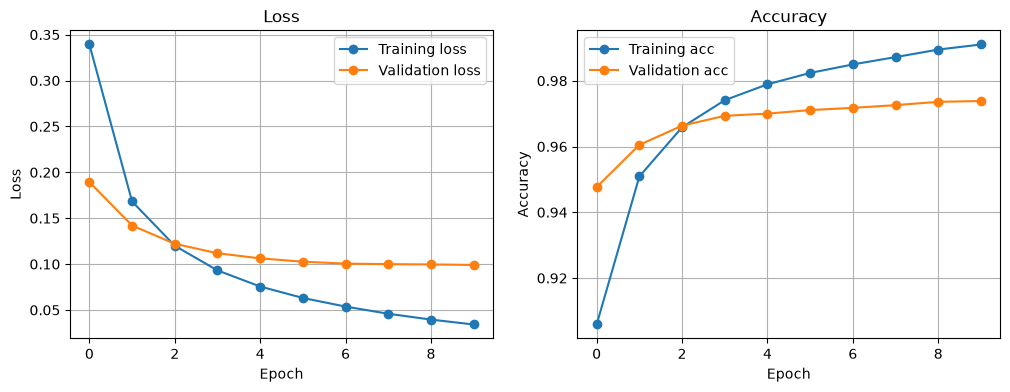

In [8]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss"); plt.legend(); plt.grid()
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], marker="o", label="Training acc")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation acc")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Accuracy"); plt.legend(); plt.grid()
plt.show()

## 5. Test on the MNIST test set

In [9]:
test_loss, test_acc = net.evaluate(X_test, y_test)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy (evaluate): {test_acc:.4f}")

# double-check by comparing predicted classes with true labels
pred_class = net.predict(X_test)
print(f"Test accuracy (manual):   {np.mean(pred_class == y_test):.4f}")
print(f"Correct: {np.sum(pred_class == y_test)} / {len(y_test)}")

Test loss: 0.0924
Test accuracy (evaluate): 0.9749
Test accuracy (manual):   0.9749
Correct: 9749 / 10000


## 6. Prediction examples

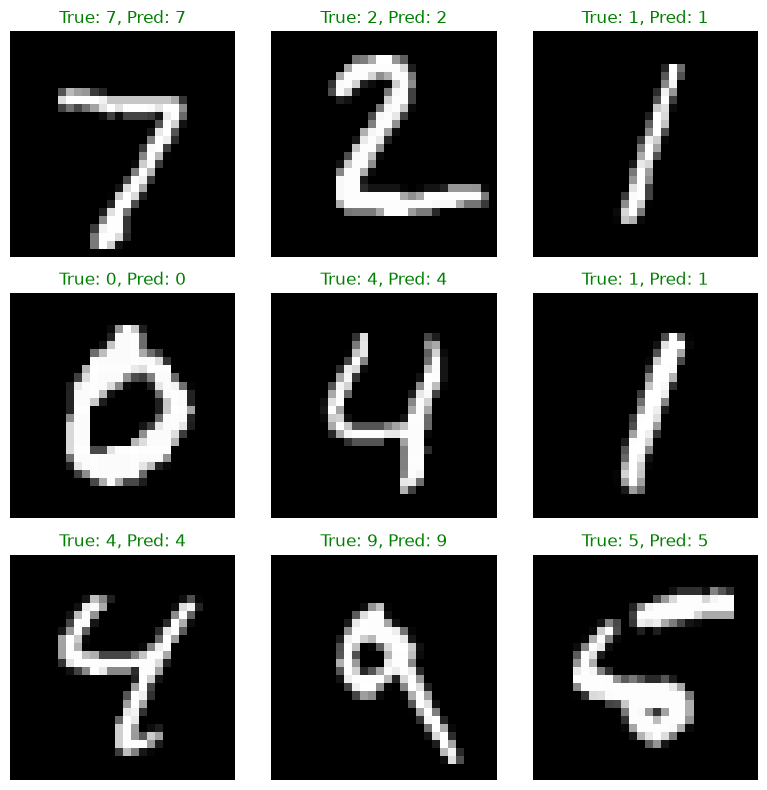

In [10]:
plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    color = "green" if pred_class[i] == y_test[i] else "red"
    plt.title(f"True: {y_test[i]}, Pred: {pred_class[i]}", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

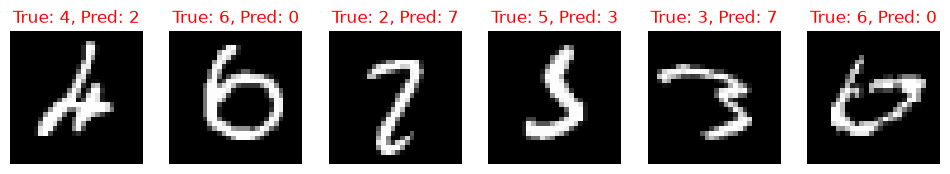

In [11]:
# a few misclassified test images
wrong = np.where(pred_class != y_test)[0][:6]
plt.figure(figsize=(12, 2.5))
for j, i in enumerate(wrong):
    plt.subplot(1, 6, j + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"True: {y_test[i]}, Pred: {pred_class[i]}", color="red")
    plt.axis("off")
plt.show()

## 7. Conclusion
- The loss goes down and the accuracy goes up every epoch, so training works.
- The test accuracy above (on 10,000 unseen images) is close to the validation accuracy, so testing works and the model generalizes.